# Baseline : statistiques simples + LightGBM

**Objectif.** Poser un premier point de comparaison : statistiques simples par session (comptes d'actions, activité totale, fréquences des actions courantes, timing) et un modèle LightGBM.

**Données.** Une ligne de `train.csv` = une session : `util,navigateur,action,action,...,tXX,...`. Une action est de la forme `Type(écran)<configuration>$chaîne$`, avec un `1` final si l'utilisateur est en modification dans la fiche. Les marqueurs `tXX` délimitent des fenêtres de temps (en secondes).

In [1]:
import re
from collections import Counter

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold

DATA = "data"
N_TOP_ACTIONS = 30  # nombre d'actions "courantes" retenues
MARQUEUR = re.compile(r"t\d+")

/Users/anas/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Lecture des sessions

On lit le CSV brut ligne par ligne (plus robuste que `read_csv` avec des lignes de longueurs très différentes). Pour chaque session on garde le navigateur, la liste des actions, le nombre d'actions par fenêtre de temps et la durée (dernier marqueur `tXX`).

In [2]:
def type_action(action: str) -> str:
    """"Exécution d'un bouton(MAINT)<DEF>$VT$1" -> "Exécution d'un bouton" (sans écran, conf, chaîne ni '1' de modification)."""
    t = re.split(r"[(<$]", action)[0]
    return t[:-1] if t.endswith("1") else t


def lire(chemin: str, avec_label: bool):
    """Une session par ligne : (util, navigateur, actions, nombre d'actions par fenêtre, durée)."""
    sessions = []
    with open(chemin, encoding="utf-8") as f:
        for ligne in f:
            champs = ligne.rstrip("\n").split(",")
            util = champs.pop(0) if avec_label else None
            navigateur, elements = champs[0], champs[1:]
            actions, par_fenetre, courant, derniere = [], [], 0, 0
            for e in elements:
                if MARQUEUR.fullmatch(e):
                    par_fenetre.append(courant)
                    courant, derniere = 0, int(e[1:])
                else:
                    actions.append(e)
                    courant += 1
            sessions.append((util, navigateur, actions, par_fenetre, derniere))
    return sessions


train = lire(f"{DATA}/train.csv", avec_label=True)
test = lire(f"{DATA}/test.csv", avec_label=False)
len(train), len(test)

(3279, 324)

## 2. Features

- **Activité totale** : `nb_actions`, `duree`, `nb_fenetres`, `actions_par_s`, `nb_types_distincts`, `part_modification`.
- **Timing** : moyenne, écart-type et maximum du nombre d'actions par fenêtre de temps.
- **Navigateur** : one-hot.
- **Actions courantes** : nombre et fréquence relative des 30 types d'action les plus fréquents.

Le vocabulaire (les 30 actions et les navigateurs) est fixé sur le **train** puis réutilisé tel quel sur le test.

In [3]:
def features(sessions, actions_courantes, navigateurs) -> pd.DataFrame:
    lignes = []
    for _, nav, actions, par_fenetre, duree in sessions:
        n = len(actions)
        types = Counter(type_action(a) for a in actions)
        w = np.array(par_fenetre) if par_fenetre else np.zeros(1)
        f = {
            # activité totale
            "nb_actions": n,
            "duree": duree,
            "nb_fenetres": len(par_fenetre),
            "actions_par_s": n / duree if duree else 0.0,
            "nb_types_distincts": len(types),
            "part_modification": sum(a.endswith("1") for a in actions) / max(n, 1),
            # timing : nombre d'actions par fenêtre de temps
            "fenetre_moy": w.mean(), "fenetre_std": w.std(), "fenetre_max": w.max(),
        }
        for nom in navigateurs:
            f[f"nav_{nom}"] = int(nav == nom)
        for t in actions_courantes:  # comptes bruts et fréquences relatives
            f[f"n_{t}"] = types[t]
            f[f"freq_{t}"] = types[t] / max(n, 1)
        lignes.append(f)
    return pd.DataFrame(lignes)


total = Counter()
for _, _, actions, _, _ in train:
    total.update(type_action(a) for a in actions)
actions_courantes = [t for t, _ in total.most_common(N_TOP_ACTIONS)]
navigateurs = sorted({s[1] for s in train})

X = features(train, actions_courantes, navigateurs)
X_test = features(test, actions_courantes, navigateurs)
classes = pd.Categorical([s[0] for s in train])
y = classes.codes
print(f"X: {X.shape}, X_test: {X_test.shape}, classes: {len(classes.categories)}")
X.iloc[:, :9].describe().T

X: (3279, 73), X_test: (324, 73), classes: 247


,count,mean,std,min,25%,50%,75%,max
nb_actions,3279.0,692.359561,1005.873878,0.0,153.000000,340.000000,818.500000,11977.000000
duree,3279.0,751.530955,1006.277841,5.0,185.000000,395.000000,945.000000,11790.000000
nb_fenetres,3279.0,157.879231,212.513833,1.0,38.000000,82.000000,197.500000,2491.000000
actions_par_s,3279.0,0.938074,0.388362,0.0,0.733333,0.880833,1.066158,9.266667
nb_types_distincts,3279.0,16.996340,4.321787,0.0,14.000000,17.000000,20.000000,29.000000
part_modification,3279.0,0.155310,0.187710,0.0,0.010703,0.090909,0.223940,0.907975
fenetre_moy,3279.0,4.406657,1.746135,0.0,3.439292,4.147541,5.003554,34.500000
fenetre_std,3279.0,4.967980,3.800642,0.0,3.341884,4.408031,5.713877,112.923929
fenetre_max,3279.0,32.252211,49.765908,0.0,17.000000,25.000000,37.000000,1859.000000


## 3. Modèle et validation croisée

LightGBM en multiclasse construit un arbre **par classe et par itération** : avec 247 classes et environ 10 sessions par classe, il faut des réglages prudents (petit pas, petites feuilles, régularisation L2). Avec `learning_rate=0.1`, 15 feuilles et sans L2, l'entraînement divergeait sur certains plis (2 % d'accuracy sur un pli).

La classe la plus rare n'a que 4 sessions : on utilise 4 plis stratifiés au maximum.

In [4]:
params = dict(n_estimators=100, learning_rate=0.05, num_leaves=7, min_child_samples=2,
              reg_lambda=5, colsample_bytree=0.7, n_jobs=-1, verbose=-1)

skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)
oof = np.zeros(len(y), dtype=int)
for i, (tr, va) in enumerate(skf.split(X, y)):
    model = lgb.LGBMClassifier(**params).fit(X.iloc[tr], y[tr])
    oof[va] = model.predict(X.iloc[va])
    print(f"pli {i}: acc={accuracy_score(y[va], oof[va]):.3f}")
print(f"CV  accuracy={accuracy_score(y, oof):.3f}  F1 macro={f1_score(y, oof, average='macro'):.3f}")

pli 0: acc=0.698
pli 1: acc=0.715
pli 2: acc=0.661
pli 3: acc=0.696
CV  accuracy=0.692  F1 macro=0.631


## 4. Variables les plus importantes

Modèle final entraîné sur tout le train ; importance mesurée par le gain.

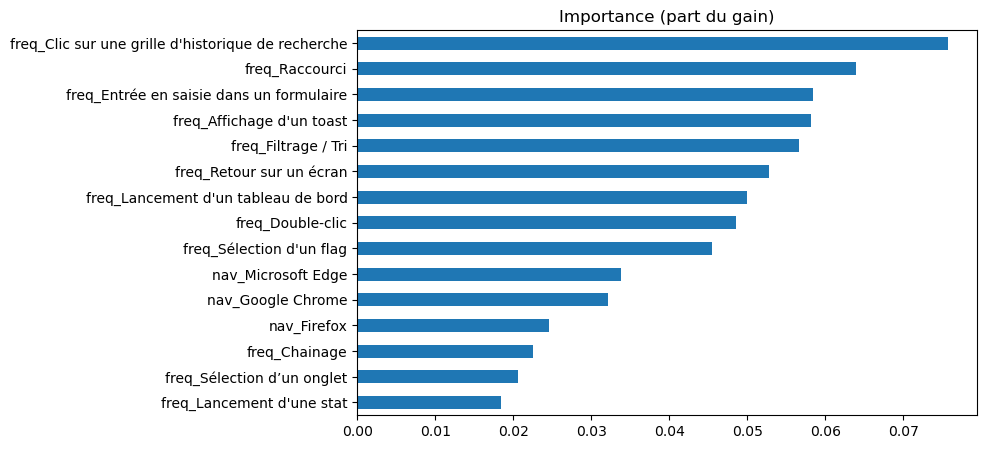

In [5]:
model = lgb.LGBMClassifier(**params).fit(X, y)
imp = pd.Series(model.booster_.feature_importance("gain"), X.columns).sort_values(ascending=False)
(imp / imp.sum()).head(15)[::-1].plot.barh(figsize=(8, 5), title="Importance (part du gain)")
plt.show()

## 5. Prédictions sur le test

In [6]:
preds = pd.Categorical.from_codes(model.predict(X_test), classes.categories)
sub = pd.DataFrame({"prediction": preds})
sub.index = sub.index + 1
sub.index.name = "RowId"
sub.to_csv("submission_baseline.csv")
sub.head()

,prediction
RowId,
1,hzx
2,prb
3,jmq
4,psg
5,cvw


## Conclusion

Cette baseline montre qu'il faut **plus de features** : les fréquences d'actions courantes portent l'essentiel du signal, mais rien ne décrit encore *où* l'utilisateur travaille (écrans, configurations, chaînes) ni l'ordre de ses actions. Un Random Forest testé hors de ce notebook sur les mêmes features fait nettement mieux que ce LightGBM (environ 83 % d'accuracy en validation croisée), ce qui suggère aussi de revoir le choix du modèle.